# Projeto 01 — Agente Inteligente de Otimização de Rotas de Distribuição Alimentar Local
## Unidade Curricular de Inteligência Artificial — IPCA (2026/2027)
### Resolução de Problemas de Pickup-and-Delivery com Janelas Temporais e Capacidade (PDPTW)

---

### Grupo 04 — `IA26_P01_G04`
* **Gonçalo Correia** — Nº 22840
* **Bruno Dantas** — Nº 27958
* **Ricardo Ferreira** — Nº 25426

**Repositório Oficial:** [https://github.com/BrunoDantas1/IA26_P01_G04.git](https://github.com/BrunoDantas1/IA26_P01_G04.git)

---

## 1. Introduction

### 1.1. Contexto do Problema e Enquadramento
A transição para cadeias de abastecimento alimentar curtas e sustentáveis coloca desafios logísticos complexos. Pequenos produtores agrícolas locais operam com margens temporais reduzidas de frescura dos produtos, enquanto os consumidores finais e mercados municipais exigem entregas em horários de conveniência bem definidos.

Neste projeto desenvolvemos um **Agente Inteligente de Planeamento de Rotas** para distribuição alimentar local na região do distrito de **Braga** e concelho da **Póvoa de Varzim**. O problema enquadra-se formalmente na classe dos **Pickup-and-Delivery Problems with Time Windows and Capacity Constraints (PDPTW)**, que combinam restrições espaciais, de precedência, temporais e de capacidade.

### 1.2. Atores e Componentes do Sistema
1. **Produtores Locais (*Producers*)**: Locais de origem onde os produtos agrícolas são colhidos/embalados e disponibilizados dentro da janela regulamentar $[\text{availability\_start}, \text{availability\_end}]$.
2. **Centros de Recolha / Armazéns (*CollectionCenters*)**: Plataformas logísticas centrais onde os bens podem ser agregados e que servem de depósito base permanente da frota de veículos.
3. **Locais de Entrega (*DeliveryLocations / Customers*)**: Clientes residenciais ou mercados municipais com janelas de entrega $[\text{delivery\_start}, \text{delivery\_end}]$.
4. **Frota de Veículos (*Vehicles*)**: Carrinhas comerciais com capacidades máximas específicas (1444.7 kg e 1009.8 kg) que realizam as viagens.
5. **Matriz de Distâncias e Tempos (*DistanceMatrix*)**: Baseada na rede de paragens unificadas de `locations.csv`, fornecendo distâncias em km (distância ortodrómica corrigida com fator rodoviário de 1.3) e tempos de viagem em minutos calculados a uma velocidade de 45 km/h.

### 1.3. Objetivos do Projeto e Divisão de Tarefas
* **Secção 1 — Introdução**: Contextualização, identificação e definição do sistema logístico.
* **Secção 2 — Exploratory Data Analysis (EDA)**: Carregamento do dataset, validação de integridade referencial e análise da procura face à frota.
* **Secção 3 — Modelação e Testes de Viabilidade**: Definição das classes `Request`, `Vehicle`, `State`, `Problem`, função de custo e validador estrito de rotas com testes manuais (*hand-written routes*).
* **Secção 4 — Problem Solving**: Parte A — pesquisa informada com Greedy e A*, incluindo duas heurísticas e comparação experimental. Inclui também pesquisa local (Hill-Climbing) e CSP com Backtracking e Forward Checking para um veículo de cada vez.
* **Secção 5 — Result Analysis & Conclusion**: Comparação dos resultados, limitações e conclusões.


In [1]:
import os
import sys

# Os notebooks vivem em notebooks/; passa para a raiz do projeto para que
# os caminhos "data_tiny" e "src" funcionem, quer se execute a partir da raiz, quer de notebooks/.
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, "src")

## 2. Exploratory Data Analysis (EDA)

Os valores seguintes foram confirmados nos 11 CSV de `data_tiny`. A análise completa consta de `02_eda_tiny.ipynb`.

### 2.1 Dimensões e integridade
| Tabela | Registos |
|---|---:|
| localities | 49 |
| producers | 5 |
| products | 23 |
| collection_centers | 1 |
| vehicles | 2 |
| customers | 8 |
| delivery_locations | 6 |
| orders | 10 |
| order_items | 23 |
| locations | 12 |
| distance_matrix | 132 |

As 10 PK simples e a chave composta da matriz são únicas e não nulas. As 12 relações FK verificadas e os mapeamentos de `locations.ref_id` são válidos. Há 132 = 12 × 11 pares dirigidos, excluindo a diagonal; o modelo atribui distância zero à diagonal.

### 2.2 Procura e capacidade
São **23 artigos de 10 encomendas**, com **248,96 kg** no total. Veículo 1: **1444,70 kg**; veículo 2: **1009,80 kg**; centro: **3232,90 kg**. Ambos os veículos têm `refrigerated=0`.

A procura representa **17,23%** da capacidade do veículo 1 ou **24,65%** do veículo 2. Capacidade em massa suficiente não demonstra uma rota única viável. O máximo por data de abertura da recolha é **43,58 kg em 19/10/2026**.

### 2.3 Janelas temporais
`ready_time = max(order_datetime, availability_start)`. Encomendar após a abertura é permitido, desde que a prontidão não ultrapasse o fecho. **12 artigos** têm prontidão após o fecho: **1, 3, 4, 9, 13, 14, 15, 16, 18, 20, 21 e 23**.

Os outros **11 artigos** são candidatos à recolha, sem garantia de viabilidade da rota. As janelas de entrega duram **1 a 4 horas** e podem ocorrer no dia seguinte à disponibilidade. Os artigos 7, 10 e 22 partilham a data de abertura, mas isso não garante uma rota conjunta viável.

### 2.4 Geografia e matriz
O centro fica em **Terras de Bouro**. Existem cinco produtores e seis destinos; as distâncias do centro aos destinos variam entre **9,14 km e 50,94 km**. O modelo usa as distâncias e durações fornecidas no CSV; as durações são compatíveis, por arredondamento, com cerca de **45 km/h**.

### 2.5 Consequências para o planeamento
Preservar os artigos originais e sinalizar os inviáveis. Validar cada rota com deslocações, espera, capacidade, precedência e regresso ao depósito. Integridade relacional e capacidade agregada não demonstram viabilidade temporal.


In [2]:
from pathlib import Path
import numpy as np
import pandas as pd

tables = {p.stem: pd.read_csv(p) for p in Path('data_tiny').glob('*.csv')}
expected = dict(localities=49, producers=5, products=23, collection_centers=1,
                vehicles=2, customers=8, delivery_locations=6, orders=10,
                order_items=23, locations=12, distance_matrix=132)
assert {name: len(frame) for name, frame in tables.items()} == expected
items = tables['order_items'].merge(tables['orders'], on='order_id').merge(tables['products'], on='product_id')
weight = (items.quantity * items.unit_weight_kg).sum()
ready = pd.concat([pd.to_datetime(items.order_datetime), pd.to_datetime(items.availability_start)], axis=1).max(axis=1)
anomalies = sorted(items.loc[ready > pd.to_datetime(items.availability_end), 'order_item_id'])
assert np.isclose(weight, 248.96)
assert anomalies == [1, 3, 4, 9, 13, 14, 15, 16, 18, 20, 21, 23]
assert tables['vehicles'].refrigerated.eq(0).all()
print(f'CSV confirmados: {weight:.2f} kg, {len(anomalies)} artigos com prontidão após o fecho.')


CSV confirmados: 248.96 kg, 12 artigos com prontidão após o fecho.


## 3. Modeling & Feasibility Tests

`model.py` define `Request`, `Vehicle`, `RouteStep`, `State` e `Problem`. O estado acompanha localização, hora, carga, artigos recolhidos/entregues e custos acumulados.

`actions` respeita capacidade, precedência e início efetivo do serviço após espera. `return_to_base` exige carga vazia e ligação viável. `is_goal` exige os artigos alvo entregues e regresso explícito ao depósito do veículo.

`route_feasibility_checker` exige partida inicial e regresso final ao depósito. Rejeita ações de depósito intermédias, duplicados, entregas sem recolha, carga por entregar, excesso de capacidade, janelas ultrapassadas após espera e ligações inválidas. Os limites temporais são inclusivos; o serviço tem duração zero.

`cost_function` aplica a mesma validação e calcula distância, viagem, espera e duração total. Uma rota inválida devolve `feasible=False` e custo infinito.

As duas rotas manuais válidas mantêm **164,51 km / 241,70 min** e **263,23 km / 351,00 min**. As demonstrações abaixo apresentam dois casos válidos e três inválidos: precedência, janela temporal e capacidade.


In [3]:
import runpy

runpy.run_path('test_handwritten_routes.py', run_name='__main__');


Pedidos válidos: 11

--- Teste Rota Válida 1 (Item 5) ---
Viável: True | Rota perfeitamente viável! Cumpre todas as restrições.
Distância: 164.51 km | Tempo: 241.7 min (Viagem: 219.4 min, Espera: 22.3 min)
  pickup (Item 5) @ Loc 4: Chegada 2026-10-10 13:26:42 -> Saída 2026-10-10 13:26:42 | Espera: 0.0m | Carga: 1.4kg
  delivery (Item 5) @ Loc 10: Chegada 2026-10-10 14:37:42 -> Saída 2026-10-10 15:00:00 | Espera: 22.3m | Carga: 0.0kg
  return (Item 6) @ Loc 6: Chegada 2026-10-10 16:01:42 -> Saída 2026-10-10 16:01:42 | Espera: 0.0m | Carga: 0.0kg

--- Teste Rota Válida 2 (Itens 10 e 7) ---
Viável: True | Rota perfeitamente viável! Cumpre todas as restrições.
Distância: 263.23 km | Tempo: 351.0 min

--- Teste Rota Inválida 1 (Precedência) ---
Viável: False | Violação de Precedência no passo 1: Tentativa de entrega do Item 5 sem ter sido previamente recolhido!

--- Teste Rota Inválida 2 (Janela Temporal) ---
Viável: False | Violação de Janela Temporal de Recolha no passo 1 (Item 5): Iníci

## 4. Problem Solving (Algoritmos de IA)

### 4.1 Parte A — Pesquisa informada

Implementámos Greedy e A* com duas heurísticas. O objetivo é encontrar rotas válidas com a menor distância possível.

#### 4.1.1 Cenário

Usámos os artigos **7 e 10**, com partida do depósito **6** a **19/10/2026, 07:30**. Ambos são recolhidos no local 4 e entregues no mesmo dia.

Os dois veículos são estudados **separadamente**: não estamos a repartir os pedidos pela frota. O `model.py` gera movimentos válidos e verifica as restrições. Os dados CSV não são alterados.


In [4]:
from time import perf_counter
from IPython.display import display
from model import Problem
from informed import (
    greedy_best_first, a_star_search,
    heuristic, heuristic_mst, reconstruct_route,
)

problem_a = Problem(data_folder="data_tiny")
target_items_a = {7, 10}
start_time_a = pd.Timestamp("2026-10-19 07:30:00")
problem_a.requests = [r for r in problem_a.requests if r.item_id in target_items_a]
problem_a.requests_by_id = {r.item_id: r for r in problem_a.requests}

vehicle_configuration_a = pd.DataFrame([
    {"Veículo": v.vehicle_id, "Depósito": v.center_location_id,
     "Capacidade (kg)": v.capacity_kg}
    for v in problem_a.vehicles.values()
])
display(vehicle_configuration_a)
display(pd.DataFrame([
    {"Artigo": r.item_id, "Peso (kg)": r.weight_kg,
     "Recolha": r.pickup_location_id, "Prontidão": r.ready_time,
     "Fim de recolha": r.availability_end, "Entrega": r.delivery_location_id,
     "Início de entrega": r.delivery_start, "Fim de entrega": r.delivery_end}
    for r in problem_a.requests
]))

,Veículo,Depósito,Capacidade (kg)
0,1,6,1444.7
1,2,6,1009.8


,Artigo,Peso (kg),Recolha,Prontidão,Fim de recolha,Entrega,Início de entrega,Fim de entrega
0,7,21.10,4,2026-10-19 08:30:00,2026-10-19 13:30:00,10,2026-10-19 11:30:00,2026-10-19 12:30:00
1,10,6.54,4,2026-10-19 07:30:00,2026-10-19 09:30:00,8,2026-10-19 08:30:00,2026-10-19 12:30:00


#### 4.1.2 Algoritmos e heurísticas

- **Greedy:** escolhe o estado com a menor estimativa da distância restante, `h(n)`; não garante a melhor rota.
- **A*:** considera a distância percorrida e a estimativa restante, `f(n) = g(n) + h(n)`.
- **Heurística 1 — maior cadeia:** usa a maior distância entre as cadeias individuais dos artigos pendentes e o regresso direto ao depósito. Cada cadeia inclui a recolha, se faltar, a entrega e o regresso.
- **Heurística 2 — árvore mínima (MST):** liga por uma árvore de custo mínimo a posição atual, o depósito e os locais de recolha e entrega ainda necessários, sem duplicados. Cada ligação usa a menor distância entre os dois sentidos.

As heurísticas ignoram espera e capacidade e fornecem limites inferiores com as distâncias não negativas e a desigualdade triangular deste dataset. Assim, o A* encontra a distância mínima neste cenário; não garante duração mínima. A MST é calculada pelo algoritmo de Prim; não altera os algoritmos de pesquisa.

A fronteira usa `heapq`. Contamos um nó expandido sempre que são gerados os sucessores desse estado.


#### 4.1.3 Execução e comparação

Executámos **8 combinações**: Greedy e A* com duas heurísticas, para cada um dos dois veículos. O cenário e a hora de partida são sempre iguais.

Registámos distância, duração, nós expandidos e tempo apenas da pesquisa, sem carregamento, validação ou apresentação. Cada rota é validada pelo `model.py`. A tabela resume os resultados e apresentamos uma rota como exemplo.


In [5]:
results_a = []
for algorithm_name_a, search_a in (("Greedy", greedy_best_first), ("A*", a_star_search)):
    for estimate_a in (heuristic, heuristic_mst):
        for vehicle_id_a in (1, 2):
            started_a = perf_counter()
            goal_a, expanded_a = search_a(problem_a, vehicle_id_a, start_time_a, estimate_a)
            elapsed_ms_a = (perf_counter() - started_a) * 1000
            if goal_a is None:
                raise RuntimeError(f"Sem solução: {algorithm_name_a}, {estimate_a.__name__}, veículo {vehicle_id_a}")
            depot_a = problem_a.vehicles[vehicle_id_a].center_location_id
            route_a = reconstruct_route(goal_a, depot_a)
            metrics_a = problem_a.cost_function(route_a, vehicle_id_a, start_time_a)
            if not metrics_a["feasible"]:
                raise RuntimeError(metrics_a["error"])
            if not results_a:
                print(f"Exemplo de rota: {route_a}")
            results_a.append({
                "Algoritmo": algorithm_name_a, "Heurística": estimate_a.__name__,
                "Veículo": vehicle_id_a, "Distância (km)": metrics_a["total_distance_km"],
                "Duração (min)": metrics_a["total_time_min"],
                "Nós expandidos": expanded_a, "Pesquisa (ms)": elapsed_ms_a,
                "Viável": metrics_a["feasible"],
            })
comparison_a = pd.DataFrame(results_a)
display(comparison_a.round({"Distância (km)": 2, "Duração (min)": 2, "Pesquisa (ms)": 3}))

Exemplo de rota: [('start', 6), ('recolha', 7), ('recolha', 10), ('entrega', 7), ('entrega', 10), ('regresso', 6)]


,Algoritmo,Heurística,Veículo,Distância (km),Duração (min),Nós expandidos,Pesquisa (ms),Viável
0,Greedy,heuristic,1,171.71,311.3,6,0.605,True
1,Greedy,heuristic,2,171.71,311.3,6,0.686,True
2,Greedy,heuristic_mst,1,171.71,311.3,8,1.192,True
3,Greedy,heuristic_mst,2,171.71,311.3,8,1.216,True
4,A*,heuristic,1,171.71,311.3,9,0.778,True
5,A*,heuristic,2,171.71,311.3,9,0.508,True
6,A*,heuristic_mst,1,171.71,311.3,11,1.182,True
7,A*,heuristic_mst,2,171.71,311.3,11,1.390,True


#### 4.1.4 Análise dos resultados

Todas as combinações encontraram uma rota válida de **171,71 km** e **311,30 min**. O Greedy encontrou aqui a mesma solução que o A*, mas não garante esse resultado em geral.

Com a primeira heurística, Greedy expandiu **6 nós** e A* **9**; com a MST, **8** e **11**, respetivamente. Uma única medição não chega para concluir qual é mais rápido.

Os dois veículos produziram os mesmos resultados porque partem do mesmo depósito e a carga escolhida cabe em ambos.

**Atenção:** esta Parte A usa só os artigos **7 e 10**. Hill-Climbing e CSP usam quatro artigos, pelo que as distâncias dessas experiências não são diretamente comparáveis.


### 4.2 Parte B — Pesquisa local (Hill-Climbing)

O objetivo é melhorar uma solução inicial por exploração iterativa de rotas vizinhas. A solução inicial vem do **Greedy Best-First** (`informed.py`), que é rápido mas não garante a rota mais curta; o Hill-Climbing parte dela e tenta reduzir a distância total. O código está em `local_search.py`.

#### 4.2.1 Cenário e formulação

Usámos os artigos **7, 10, 17 e 22**, com partida em **19/10/2026 às 07:30** do depósito **6**. Com apenas os artigos 7 e 10 o Greedy já devolve a rota ótima, pelo que não haveria nada a melhorar; com quatro artigos há margem para a pesquisa local.

* **Solução:** rota completa `[("start", 6), ..., ("regresso", 6)]`, com as recolhas e entregas dos quatro artigos.
* **Custo:** distância total em km (critério de desempate: duração em minutos). Uma rota inviável tem custo infinito.
* **Vizinhança:** movimentos *relocate* (mover um passo para outra posição) e *swap* (trocar dois passos). A partida e o regresso ao depósito mantêm-se fixos. Cada vizinho é validado por `route_feasibility_checker()` e avaliado por `cost_function()`, pelo que a precedência, a capacidade e as janelas temporais são sempre respeitadas.
* **Algoritmo:** Hill-Climbing de melhor vizinho (*steepest ascent*). Em cada iteração avalia toda a vizinhança e move-se para o melhor vizinho, se este for estritamente melhor. Pára no primeiro ótimo local.

In [6]:
import random
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from model import Problem
from informed import greedy_best_first, heuristic, reconstruct_route
from local_search import hill_climbing, random_restart_hill_climbing

items_b = [7, 10, 17, 22]
start_time_b = pd.Timestamp("2026-10-19 07:30:00")

problem_b = Problem(data_folder="data_tiny")
problem_b.requests = [r for r in problem_b.requests if r.item_id in items_b]
problem_b.requests_by_id = {r.item_id: r for r in problem_b.requests}

# Resumo dos artigos do cenário
display(pd.DataFrame([{
    "Artigo": r.item_id, "Peso (kg)": round(r.weight_kg, 2),
    "Recolha (local)": r.pickup_location_id, "Entrega (local)": r.delivery_location_id,
    "Janela de recolha": f"{r.availability_start:%d/%m %H:%M}–{r.availability_end:%H:%M}",
    "Janela de entrega": f"{r.delivery_start:%d/%m %H:%M}–{r.delivery_end:%H:%M}",
} for r in problem_b.requests]))

,Artigo,Peso (kg),Recolha (local),Entrega (local),Janela de recolha,Janela de entrega
0,7,21.10,4,10,19/10 08:30–13:30,19/10 11:30–12:30
1,10,6.54,4,8,19/10 07:30–09:30,19/10 08:30–12:30
2,17,10.40,1,9,19/10 10:00–16:00,20/10 13:00–15:00
3,22,2.64,4,8,19/10 12:15–15:15,19/10 16:15–18:15


#### 4.2.2 Execução: Greedy → Hill-Climbing

Para cada veículo, o Greedy (heurística `heuristic`) gera a rota inicial e o Hill-Climbing melhora-a. O tempo do Hill-Climbing mede apenas a pesquisa; a rota final é confirmada pelo validador.

In [7]:
results_b = []
histories_b = {}
for vehicle_id in (1, 2):
    depot = problem_b.vehicles[vehicle_id].center_location_id
    goal, _ = greedy_best_first(problem_b, vehicle_id, start_time_b, heuristic)
    initial_route = reconstruct_route(goal, depot)

    result = hill_climbing(problem_b, initial_route, vehicle_id, start_time_b)

    # Confirmação da rota final com o validador
    feasible, reason, _ = problem_b.route_feasibility_checker(
        result["route"], vehicle_id, start_time_b)
    assert feasible, reason

    histories_b[vehicle_id] = result["history"]
    results_b.append({
        "Veículo": vehicle_id,
        "Greedy (km)": result["history"][0],
        "Hill-Climbing (km)": result["distance_km"],
        "Melhoria (km)": result["history"][0] - result["distance_km"],
        "Duração (min)": result["duration_min"],
        "Iterações": result["iterations"],
        "Vizinhos avaliados": result["evaluated"],
        "Tempo (ms)": result["time_ms"],
        "Viável": feasible,
    })
    print(f"Veículo {vehicle_id} — rota final:")
    for step in result["route"]:
        print("   ", step)

display(pd.DataFrame(results_b).round(2))

Veículo 1 — rota final:
    ('start', 6)
    ('recolha', 7)
    ('recolha', 10)
    ('entrega', 10)
    ('recolha', 17)
    ('entrega', 7)
    ('recolha', 22)
    ('entrega', 22)
    ('entrega', 17)
    ('regresso', 6)
Veículo 2 — rota final:
    ('start', 6)
    ('recolha', 7)
    ('recolha', 10)
    ('entrega', 10)
    ('recolha', 17)
    ('entrega', 7)
    ('recolha', 22)
    ('entrega', 22)
    ('entrega', 17)
    ('regresso', 6)


,Veículo,Greedy (km),Hill-Climbing (km),Melhoria (km),Duração (min),Iterações,Vizinhos avaliados,Tempo (ms),Viável
0,1,343.91,304.69,39.22,1802.2,2,210,16.79,True
1,2,343.91,304.69,39.22,1802.2,2,210,19.50,True


#### 4.2.3 Curva de custo por iteração

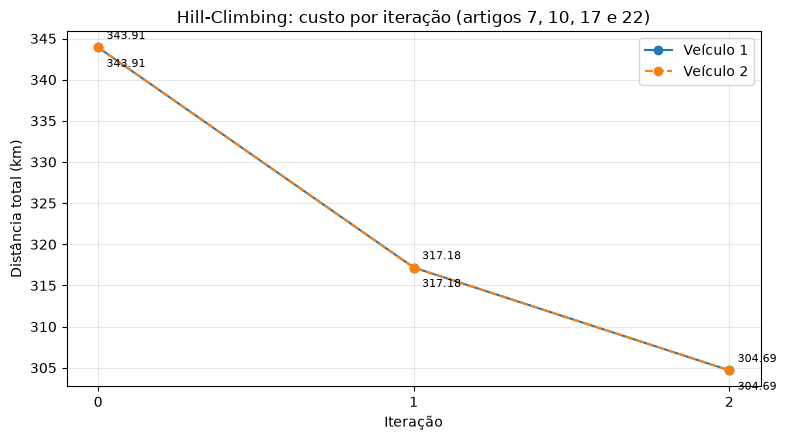

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for vehicle_id, history in histories_b.items():
    ax.plot(range(len(history)), history, marker="o", linestyle="--" if vehicle_id == 2 else "-",
            label=f"Veículo {vehicle_id}")
    for it, cost in enumerate(history):
        ax.annotate(f"{cost:.2f}", (it, cost), textcoords="offset points",
                    xytext=(6, 6 if vehicle_id == 1 else -14), fontsize=8)
ax.set_xlabel("Iteração")
ax.set_ylabel("Distância total (km)")
ax.set_title("Hill-Climbing: custo por iteração (artigos 7, 10, 17 e 22)")
ax.set_xticks(range(max(len(h) for h in histories_b.values())))
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

#### 4.2.4 Reinícios aleatórios (verificação do ótimo local)

O Hill-Climbing simples pára no primeiro ótimo local, que pode não ser o melhor. Para o testar, repetimos a pesquisa a partir de 10 rotas viáveis aleatórias (semente fixa) e guardamos a melhor.

In [9]:
rr = random_restart_hill_climbing(problem_b, items_b, 1, start_time_b, restarts=10, seed=42)
print(f"Reinícios aleatórios (10): melhor distância = {rr['distance_km']:.2f} km, "
      f"duração = {rr['duration_min']:.2f} min, tempo total = {rr['time_ms']:.1f} ms")

Reinícios aleatórios (10): melhor distância = 304.69 km, duração = 1802.20 min, tempo total = 943.9 ms


#### 4.2.5 Análise crítica

**Qualidade da solução.** O Greedy devolve uma rota de **343,91 km**; o Hill-Climbing reduz-a para **304,69 km** (−39,22 km, cerca de 11%) em apenas 2 iterações. É uma solução válida melhor do que a inicial. A demonstração não compara exaustivamente as rotas nem executa A* neste cenário de quatro artigos, pelo que não permite afirmar que seja o ótimo global.

**Comportamento.** A melhoria vem de reordenar recolhas e entregas: em vez de entregar tudo no fim, o Hill-Climbing intercala passos de forma a reduzir deslocações, sem violar as janelas temporais (cada vizinho inviável tem custo infinito e nunca é escolhido). As curvas dos dois veículos são iguais porque partem do mesmo depósito, usam a mesma matriz de distâncias e as capacidades são muito superiores à carga transportada.

**Duração.** A duração (1802 min) é elevada porque inclui a espera pela janela de entrega do artigo 17, que só abre a 20/10 às 13:00; a otimização é feita sobre a distância, não sobre a duração.

**Limitações.** O Hill-Climbing só aceita melhorias estritas, por isso pode ficar preso num ótimo local ou num planalto; a qualidade depende da solução inicial e da vizinhança. Os reinícios aleatórios reduzem esse risco, e aqui convergiram para o mesmo valor, sem demonstrar optimalidade global. Com poucos artigos, a vizinhança é pequena (cerca de 70 vizinhos por iteração); com mais artigos cresce quadraticamente e o custo de avaliação aumentaria.

**Custo computacional.** Os tempos são de uma única execução e dependem do ambiente, pelo que não sustentam conclusões sobre desempenho relativo. Fica como melhoria futura medir em vários cenários maiores e testar vizinhanças adicionais (por exemplo, mover pares recolha–entrega) ou simulated annealing.

### 4.3 Parte C — CSP (Constraint Satisfaction Problem)

Usamos os artigos **7, 10, 17 e 22** do dataset original, com **40,68 kg**, partida em **19/10/2026 às 07:30**. Resolvemos o mesmo cenário separadamente para cada veículo. `CSPProblemModel` recebe o `Problem` e reutiliza os seus objetos `Request`; os CSV não são alterados.

* **Variáveis:** posições $X_1,\ldots,X_8$ entre a partida e o regresso fixos ao depósito do veículo.
* **Domínios:** as oito ações reais `(recolha, item_id)` e `(entrega, item_id)`, uma de cada tipo por artigo. São apresentados abaixo.
* **Unicidade e cobertura:** cada ação aparece exatamente uma vez; todos os artigos selecionados são entregues.
* **Precedência:** a recolha precede a entrega do mesmo artigo, no mesmo veículo.
* **Tempo e deslocação:** a matriz fornece cada duração. O serviço começa em `max(chegada, ready_time)` na recolha e `max(chegada, delivery_start)` na entrega, sem ultrapassar o respetivo fecho. `ready_time = max(order_datetime, availability_start)`. A espera é permitida, os limites são inclusivos e o serviço tem duração zero, conforme o modelo existente. Não há discretização nem folgas artificiais.
* **Capacidade e depósito:** a carga acumulada nunca excede a capacidade do veículo e todas as entregas precedem o regresso ao depósito, sem carga.

A ordem das posições e dos valores é fixa. O Backtracking verifica cada candidato antes de atribuir. O **Forward Checking** verifica ainda cada valor de cada variável não atribuída contra a atribuição atual, elimina incompatibilidades e abandona o ramo se um domínio ficar vazio. Não impõe consistência de arco entre variáveis futuras. Com lacunas, a viabilidade temporal é verificada apenas no prefixo consecutivo conhecido; a unicidade e as precedências já decididas continuam a ser verificadas. A solução completa é confirmada por `route_feasibility_checker`.

**Retrocesso:** remoção de uma atribuição consistente cujo ramo não encontrou solução. Uma tentativa rejeitada antes da atribuição não conta como retrocesso. Ambos procuram a primeira solução válida, sem otimizar a distância.


In [10]:
from csp import CSPProblemModel, CSPSearchEngine

problem_csp = Problem(data_folder="data_tiny")
items_csp = [7, 10, 17, 22]
start_csp = pd.Timestamp("2026-10-19 07:30")
models_csp = {vid: CSPProblemModel(problem_csp, items_csp, vid, start_csp)
              for vid in (1, 2)}
model_csp = models_csp[1]
print("Variáveis:", [f"X_{p}" for p in model_csp.variables])
display(pd.DataFrame([{"variável": f"X_{p}", "domínio": values}
                      for p, values in model_csp.domains.items()]))
display(pd.DataFrame([{
    "artigo": r.item_id, "peso_kg": r.weight_kg,
    "local_recolha": r.pickup_location_id, "local_entrega": r.delivery_location_id,
    "recolha_desde": r.ready_time, "recolha_até": r.availability_end,
    "entrega_desde": r.delivery_start, "entrega_até": r.delivery_end,
} for r in model_csp.requests]))
display(pd.DataFrame([{"veículo": vid, "capacidade_kg": m.vehicle.capacity_kg,
                       "depósito": m.vehicle.center_location_id}
                      for vid, m in models_csp.items()]))

results_csp = []
summary_csp = []
for vid, model in models_csp.items():
    for forward in (False, True):
        result = CSPSearchEngine(model).backtracking(use_forward_checking=forward)
        assert result["feasible"], result["message"]
        valid, message, details = model.validate_solution(result["assignment"])
        assert valid, message
        assert details["delivered_items_count"] == len(items_csp)
        results_csp.append(result)
        print(f"\nVeículo {vid} — {result['algorithm']}")
        print("Solução:", result["assignment"])
        print("Rota:", result["route"])
        print(message)
        display(pd.DataFrame(details["log"]))
        summary_csp.append({
            "veículo": vid, "algoritmo": result["algorithm"], "válida": valid,
            "retrocessos": result["backtracks"], "tentativas": result["attempts"],
            "nós": result["nodes"], "valores_eliminados": result["pruned_values"],
            "tempo_s": result["elapsed_seconds"],
            "distância_km": details["total_distance_km"],
            "duração_min": details["total_time_min"],
        })
display(pd.DataFrame(summary_csp))
assert model_csp.domains == CSPProblemModel(problem_csp, items_csp, 1, start_csp).domains

# Caso inviável real: o artigo 1 só fica pronto após fechar a recolha.
request_bad_csp = problem_csp.requests_by_id[1]
assert request_bad_csp.ready_time > request_bad_csp.availability_end
for forward in (False, True):
    impossible_csp = CSPProblemModel(problem_csp, [1], 1, request_bad_csp.ready_time)
    failure_csp = CSPSearchEngine(impossible_csp).backtracking(forward)
    assert failure_csp["assignment"] is None and not failure_csp["feasible"]
print("Artigo 1: ambos os algoritmos confirmam ausência de solução.")


Variáveis: ['X_1', 'X_2', 'X_3', 'X_4', 'X_5', 'X_6', 'X_7', 'X_8']


,variável,domínio
0,X_1,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
1,X_2,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
2,X_3,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
3,X_4,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
4,X_5,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
5,X_6,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
6,X_7,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."
7,X_8,"[(recolha, 7), (entrega, 7), (recolha, 10), (e..."


,artigo,peso_kg,local_recolha,local_entrega,recolha_desde,recolha_até,entrega_desde,entrega_até
0,7,21.10,4,10,2026-10-19 08:30:00,2026-10-19 13:30:00,2026-10-19 11:30:00,2026-10-19 12:30:00
1,10,6.54,4,8,2026-10-19 07:30:00,2026-10-19 09:30:00,2026-10-19 08:30:00,2026-10-19 12:30:00
2,17,10.40,1,9,2026-10-19 10:00:00,2026-10-19 16:00:00,2026-10-20 13:00:00,2026-10-20 15:00:00
3,22,2.64,4,8,2026-10-19 12:15:00,2026-10-19 15:15:00,2026-10-19 16:15:00,2026-10-19 18:15:00


,veículo,capacidade_kg,depósito
0,1,1444.7,6
1,2,1009.8,6



Veículo 1 — Backtracking
Solução: {1: ('recolha', 7), 2: ('recolha', 10), 3: ('entrega', 7), 4: ('entrega', 10), 5: ('recolha', 17), 6: ('recolha', 22), 7: ('entrega', 22), 8: ('entrega', 17)}
Rota: [('start', 6), ('recolha', 7), ('recolha', 10), ('entrega', 7), ('entrega', 10), ('recolha', 17), ('recolha', 22), ('entrega', 22), ('entrega', 17), ('regresso', 6)]
Rota perfeitamente viável! Cumpre todas as restrições.


,step,action,item_id,location_id,arrival,departure,wait_min,load_kg
0,1,recolha,7,4,2026-10-19 08:56:42,2026-10-19 08:56:42,0.0,21.10
1,2,recolha,10,4,2026-10-19 08:56:42,2026-10-19 08:56:42,0.0,27.64
2,3,entrega,7,10,2026-10-19 10:07:42,2026-10-19 11:30:00,82.3,6.54
3,4,entrega,10,8,2026-10-19 12:20:18,2026-10-19 12:20:18,0.0,0.00
4,5,recolha,17,1,2026-10-19 13:11:24,2026-10-19 13:11:24,0.0,10.40
5,6,recolha,22,4,2026-10-19 14:39:48,2026-10-19 14:39:48,0.0,13.04
6,7,entrega,22,8,2026-10-19 15:45:36,2026-10-19 16:15:00,29.4,10.40
7,8,entrega,17,9,2026-10-19 16:28:00,2026-10-20 13:00:00,1232.0,0.00
8,9,regresso,6,6,2026-10-20 13:32:12,2026-10-20 13:32:12,0.0,0.00


... (4 outputs left out)


Veículo 2 — Forward Checking
Solução: {1: ('recolha', 7), 2: ('recolha', 10), 3: ('entrega', 7), 4: ('entrega', 10), 5: ('recolha', 17), 6: ('recolha', 22), 7: ('entrega', 22), 8: ('entrega', 17)}
Rota: [('start', 6), ('recolha', 7), ('recolha', 10), ('entrega', 7), ('entrega', 10), ('recolha', 17), ('recolha', 22), ('entrega', 22), ('entrega', 17), ('regresso', 6)]
Rota perfeitamente viável! Cumpre todas as restrições.


,step,action,item_id,location_id,arrival,departure,wait_min,load_kg
0,1,recolha,7,4,2026-10-19 08:56:42,2026-10-19 08:56:42,0.0,21.10
1,2,recolha,10,4,2026-10-19 08:56:42,2026-10-19 08:56:42,0.0,27.64
2,3,entrega,7,10,2026-10-19 10:07:42,2026-10-19 11:30:00,82.3,6.54
3,4,entrega,10,8,2026-10-19 12:20:18,2026-10-19 12:20:18,0.0,0.00
4,5,recolha,17,1,2026-10-19 13:11:24,2026-10-19 13:11:24,0.0,10.40
5,6,recolha,22,4,2026-10-19 14:39:48,2026-10-19 14:39:48,0.0,13.04
6,7,entrega,22,8,2026-10-19 15:45:36,2026-10-19 16:15:00,29.4,10.40
7,8,entrega,17,9,2026-10-19 16:28:00,2026-10-20 13:00:00,1232.0,0.00
8,9,regresso,6,6,2026-10-20 13:32:12,2026-10-20 13:32:12,0.0,0.00


,veículo,algoritmo,válida,retrocessos,tentativas,nós,valores_eliminados,tempo_s,distância_km,duração_min
0,1,Backtracking,True,15,156,24,0,0.179520,343.91,1802.2
1,1,Forward Checking,True,15,23,16,115,0.394869,343.91,1802.2
2,2,Backtracking,True,15,156,24,0,0.109014,343.91,1802.2
3,2,Forward Checking,True,15,23,16,115,0.392837,343.91,1802.2


Artigo 1: ambos os algoritmos confirmam ausência de solução.


#### 4.3.1 Resultado e limitações

Ambos encontram uma rota válida de **343,91 km** para cada veículo: depósito 6, recolhas 7 e 10, entregas 7 e 10, recolhas 17 e 22, entregas 22 e 17, regresso ao depósito 6. Há **15 retrocessos** em cada execução. O Forward Checking reduz as tentativas de **156 para 23** e os nós de **24 para 16**, eliminando **115 valores**. O seu custo adicional de verificação pode aumentar o tempo neste cenário pequeno; menos nós não garantem menor tempo.

A distância coincide com a solução inicial do Greedy; o Hill-Climbing encontra 304,69 km no mesmo cenário. O CSP demonstra satisfação de restrições, sem garantir distância mínima. A capacidade é verificada, mas não é limitante nestes dados. O artigo 1 demonstra ausência de solução com dados reais. Não se alteram capacidades, pedidos nem janelas para fabricar conflitos.

O espaço de permutações cresce fatorialmente. Esta formulação destina-se à demonstração académica com poucos artigos e um veículo fixo por execução; não coordena simultaneamente a frota. Os horários são os mais cedo possíveis para cada sequência, o que é suficiente para decidir viabilidade com espera permitida e serviço de duração zero.


## 5. Result Analysis & Conclusion

| Componente | Artigos | Resultado |
|---|---|---|
| Greedy e A*, duas heurísticas e dois veículos | 7 e 10 | Oito rotas válidas de 171,71 km e 311,30 min |
| Hill-Climbing, para cada veículo | 7, 10, 17 e 22 | Melhora a rota do Greedy de 343,91 km para 304,69 km em duas iterações |
| Backtracking e Forward Checking, para cada veículo | 7, 10, 17 e 22 | Rotas válidas de 343,91 km e 15 retrocessos; o Forward Checking reduz as tentativas de 156 para 23 |

O A* encontra a distância mínima no cenário da Parte A com as heurísticas admissíveis usadas. O Greedy coincide com esse resultado, sem garantia geral de optimalidade. O Hill-Climbing melhora a solução inicial no cenário de quatro artigos, mas pode ficar preso em ótimos locais. Os 304,69 km são o melhor valor observado nesta experiência, sem prova de optimalidade global. O CSP encontra uma solução que satisfaz as restrições, sem otimizar a distância.

As distâncias da Parte A não são diretamente comparáveis com as restantes experiências, pois os conjuntos de artigos diferem. Todos os métodos reutilizam o modelo e a validação das rotas. A espera pelas janelas pode aumentar a duração mesmo quando a distância melhora.

Os cenários são pequenos e os veículos são avaliados separadamente. Não se demonstra escalabilidade nem coordenação simultânea da frota. Os tempos medidos numa única execução não permitem concluir qual método é mais rápido. Os dados incluem artigos inviáveis: o artigo 1 é rejeitado por ambos os algoritmos CSP porque fica pronto após o fecho da recolha.

**Conclusão.** Foram alcançados os objetivos de modelar o problema, encontrar rotas válidas e comparar pesquisa informada, pesquisa local e satisfação de restrições. Os principais desafios foram conciliar precedência, capacidade e janelas temporais, incluindo pedidos inviáveis nos dados. O trabalho usou Python, pandas, NumPy, Matplotlib e Jupyter. Como melhorias futuras, propomos avaliar cenários maiores com medições repetidas e estudar a distribuição dos pedidos por vários veículos.
